In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import os
# import re

In [2]:
from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [3]:
df = pd.read_csv(os.path.join('..', 'experiments', 'keep_questionable', 'final_data.csv')) 

In [4]:
df = df[~df['fish'].str.contains('ctrl', case=False, na=False)]
df = df[df['sample'] == 1]

In [5]:
barcode_fish_appearances = (
    df.groupby("barcode")["fish"]
      .nunique()
      .rename("n_unique_fish")
)

def get_fish_barcodes(fish):
    """
    This function inputs a fish and returns a dataframe with the following columns:
    - barcode
    - reads
    - unique (boolean, True if the barcode does not appear in any other fish)
    """
    fish_barcodes = df[df['fish'] == fish].groupby('barcode', as_index = False).agg({'reads': 'sum'})
    fish_barcodes = fish_barcodes.join(
        barcode_fish_appearances.eq(1).rename("unique"),
        on="barcode"
    ).sort_values('reads', ascending = False)

    return fish_barcodes

In [6]:
df[df['barcode'] == '40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NONE_NONE_NONE']

,barcode,fish,sample,replicate,file,reads,proportion
2704,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fish21,1,1,fish21_s1_rep1,2422,0.113592
2709,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fish21,1,2,fish21_s1_rep2,3082,0.147804
2714,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fish21,1,3,fish21_s1_rep3,3696,0.175640
5832,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fish45,1,1,fish45_s1_rep1,554,0.040810
5836,40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NO...,fish45,1,3,fish45_s1_rep3,4933,0.121121


In [7]:
get_fish_barcodes('fish45').loc[3]['barcode']

'40D+18_NONE_NONE_2I+118+TT_1D+145_NONE_NONE_NONE_NONE_NONE'

In [8]:
def plot_pie(ax, fish):
    fish_barcodes = get_fish_barcodes(fish)

    out = (
        fish_barcodes.groupby('unique')['reads']
          .sum()
          .reindex([False, True], fill_value=0)
    )
    percent_true = out.loc[True] / out.sum()
    
    sizes = fish_barcodes["reads"]
    colors = fish_barcodes["unique"].map({True: "#36025c", False: "#D7C9F28C"})

    wedges, _ = ax.pie(
        sizes,
        labels=None,
        colors=colors,
        startangle=90,
        counterclock=False,
        wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
        radius=1.0
    )

    fish_number = ''.join(filter(str.isdigit, fish_name))
    formatted_title = f"Fish {fish_number} ({100*percent_true:.0f}%)"

    ax.set_title(formatted_title, fontsize=7, pad=1, fontweight='bold')

/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_88639/3648783108.py:7: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0, hspace=0.3)


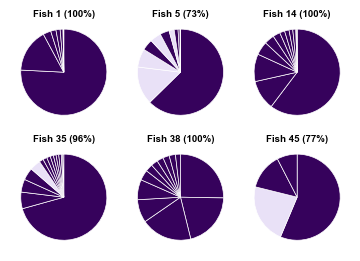

In [13]:
fishes = ['fish1', 'fish5', 'fish14', 'fish35', 'fish38', 'fish45']
fishes = sorted(fishes, key=lambda x: int(x.replace("fish", "")))

n_rows = 2
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize = (3.5, 2.5), constrained_layout = True)
plt.subplots_adjust(wspace=0, hspace=0.3)

ax = axes.ravel()
for i, fish_name in enumerate(fishes):
    plot_pie(ax[i], fish_name)
    
# for i in range(32, 36):
#     ax[i].set_visible(False)

# plt.tight_layout()
plt.savefig(os.path.join('images', 'pie_charts', 'pie.png'), dpi = 300)
plt.savefig(os.path.join('images', 'pie_charts', 'pie.svg'))

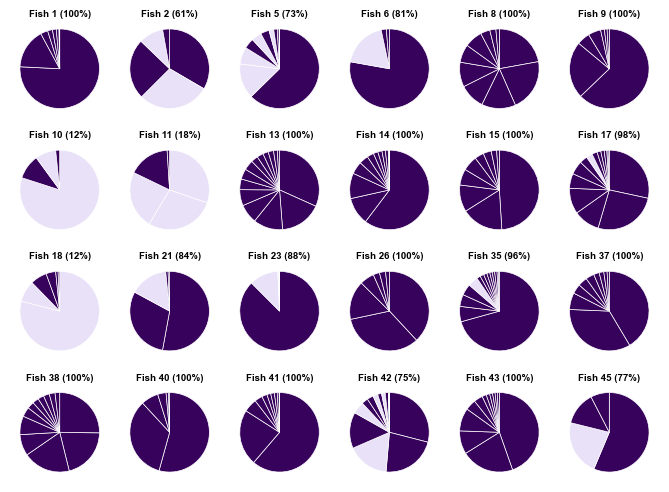

In [11]:
fishes = df['fish'].unique()
fishes = sorted(fishes, key=lambda x: int(x.replace("fish", "")))

n_rows = 4
n_cols = 6
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.7, 5))
# plt.subplots_adjust(wspace=0, hspace=0.3)

ax = axes.ravel()
for i, fish_name in enumerate(fishes):
    plot_pie(ax[i], fish_name)
    
# for i in range(32, 36):
#     ax[i].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join('images', 'pie_charts', 'all_pies.png'), dpi = 300)
plt.savefig(os.path.join('images', 'pie_charts', 'all_pies.svg'))

In [12]:
g = df.groupby('barcode').agg({'fish': 'nunique'})
v = g.value_counts()

percent_unique = v[1] / (v.sum() - 1)
print(f'{(1-percent_unique)*100:.1f}% of barcodes are shared.')

2.7% of barcodes are shared.
